
## Задача - Предсказать поведение клиентов (отток) с целью разработки программ удержания клиентов (датасет от kaggle)


Набор данных (каждая строка представляет клиента) включает информацию о:

    Клиентах, которые ушли в течение последнего месяца – колонка Churn
    
    Услуги, на которые подписан каждый клиент - телефон (PhoneService), несколько линий (MultipleLines), интернет (InternetService), онлайн-безопасность (OnlineSecurity), онлайн-резервное копирование (OnlineBackup), защита устройств (DeviceProtection), техническая поддержка (TechSupport), потоковое телевидение (StreamingTV), фильмы (StreamingMovies)
    
    Информация об учетной записи клиента - продолжительность сотрудничества (tenure), тип контракта (Contract), способ оплаты (PaymentMethod), способ выставления счетов (PaperlessBilling), ежемесячные платежи (MonthlyCharges) и общие расходы (TotalCharges)
    
    Соц-демографическая информация о клиентах – пол (gender), возрастной диапазон (SeniorCitizen), есть ли партнеры (Partner) и иждивенцы (Dependents)


In [2]:
# Качаем и распаковываем датасет
!curl -L -o telco-customer-churn.zip https://www.kaggle.com/api/v1/datasets/download/blastchar/telco-customer-churn
!tar -xf telco-customer-churn.zip
!unzip telco-customer-churn.zip

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0           00:01              0
  0      0   0      0   0      0      0      0           00:01              0

  0      0   0      0   0      0      0      0           00:01              0
100 171.6k 100 171.6k   0      0  84317      0   00:02   00:02              0
100 171.6k 100 171.6k   0      0  84309      0   00:02   00:02              0
100 171.6k 100 171.6k   0      0  84300      0   00:02   00:02              0
"unzip" ­Ґ пў«пҐвбп ў­гваҐ­­Ґ© Ё«Ё ў­Ґи­Ґ©
Є®¬ ­¤®©, ЁбЇ®«­пҐ¬®© Їа®Ја ¬¬®© Ё«Ё Ї ЄҐв­л¬ д ©«®¬.


для работы нам нужны следующие библиотеки

In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

from phik import report

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import make_column_selector as selector
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import auc
from sklearn.metrics import roc_curve
from sklearn.metrics import RocCurveDisplay

from sklearn.inspection import permutation_importance

# Загрузка данных

In [3]:
data = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
data.Churn.value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Построение любой модели начинается с анализа данных и подготовки датасета

Посмотрим данные на предмет типов, в данных есть столбец TotalCharges с типом object, его нужно конвертировать в числовой тип, а SeniorCitizen - наоборот, нужно перевести в строковое значение, иначе линейная модель воспримет значения как порядковые. Еще есть айдишники, их нужно удалить

In [5]:
data.dtypes.to_frame()

,0
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


In [6]:
data['TotalCharges'] = data['TotalCharges'].apply(pd.to_numeric, errors="coerce")
data['SeniorCitizen'] = data['SeniorCitizen'].astype('str')
data = data.drop(['customerID'], axis=1)
data.dtypes.to_frame()

,0
gender,str
SeniorCitizen,str
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str
OnlineBackup,str


Делим датасет на фичи и таргет, т е на X-сы и y (то что нужно предсказать Churn)

In [7]:
X_ = data.drop(['Churn'], axis=1)
y_ = data['Churn'].replace({"Yes": 1, "No": 0})
y_ = y_.astype(int)

Мы не можем готовить датасет на всех данных, так как это будет нечестным подглядываем в данные для теста, поэтому до обработки данных нужно отделить тестовые данные от тренировочных 

Делим наш датасет на данные для обучения и теста

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_,
    y_,
    test_size=0.15,
    random_state=211 # отвечает за случайность разделения
)

In [9]:
X_train.shape, X_test.shape

((5986, 19), (1057, 19))

# EDA анализ

сделаем некое подобие разведовательного анализа для наброски первых гипотез и поиска аномалий в данных

In [10]:
categorical_cols = X_train.select_dtypes(exclude=np.number).columns
numerical_cols = X_train.select_dtypes(include=np.number).columns
categorical_cols, numerical_cols

(Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
        'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
        'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
        'Contract', 'PaperlessBilling', 'PaymentMethod'],
       dtype='str'),
 Index(['tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str'))

In [11]:
data_train = pd.concat((X_train, y_train), axis=1)

построим графики числовых фичей

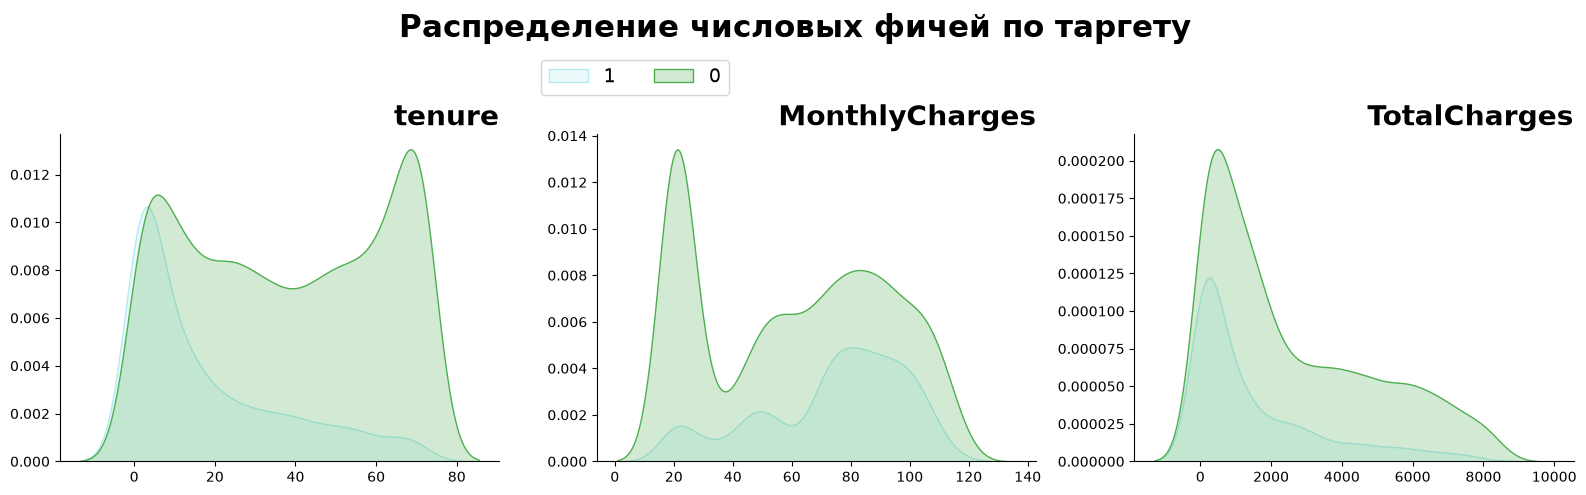

In [12]:
# 1. Отбираем только числовые колонки
data_numerical = data_train.select_dtypes(include=['number'])

# Сразу убираем таргет 'Churn' из списка графиков, чтобы он не строился сам на себя
numerical_cols = data_numerical.columns.tolist()
if 'Churn' in numerical_cols:
    numerical_cols.remove('Churn')

# Установим размер полотна
figsize = (4*4, 5)
fig = plt.figure(figsize=figsize)

# Для каждой числовой колонки изобразим график
for idx, col in enumerate(numerical_cols):
    ax = plt.subplot(1, 3, idx + 1) 

    sns.kdeplot(
        data=data_train,
        x=col,
        hue='Churn',
        fill=True,
        palette=['#4CAF50', '#B3EBF2'],
        legend=False
    )

    # Настройки подписей на осях и названий subplots
    ax.set_ylabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlabel('')
    ax.set_title(f'{col}', loc='right', weight='bold', fontsize=20) 

# Глобальные титул и легенда (центрировано)
fig.suptitle(f'Распределение числовых фичей по таргету\n', ha='center',  fontweight='bold', fontsize=22)
fig.legend([1, 0], loc='upper center', bbox_to_anchor=(0.4, 0.9), fontsize=14, ncol=3)
 
plt.tight_layout()
plt.show()


Кажется, что основными фичами будут продолжительность и ежемесячная плата, так как третья фича - total charges это произведение ежеемесячгых платежей и продолжительности сотрудничества. 

Те, кто с большей вероятностью уйдут - это новые клиенты (маленький tenure), которые подключили дорогие тарифы или дополнительные услуги (высокий MonthlyCharges).

посмотрим распределение категориальных фичей

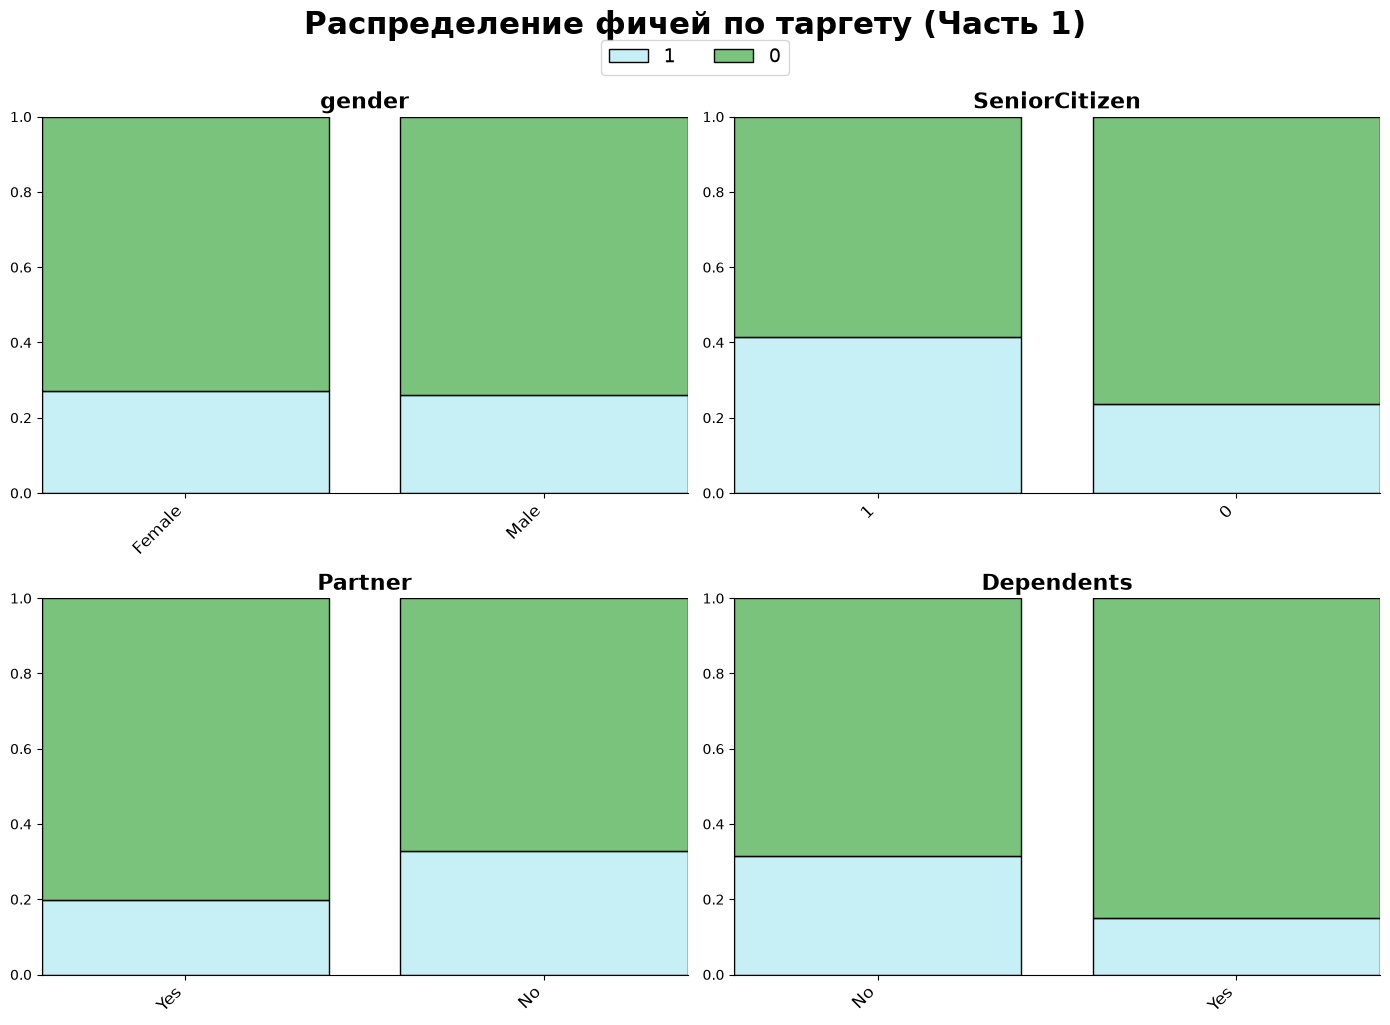

In [13]:
# 1. Отбираем только категориальные колонки (исключая числовые)
categorical_cols = data_train.select_dtypes(exclude=np.number).columns.tolist()

if 'Churn' in categorical_cols:
    categorical_cols.remove('Churn')

# Функция для отрисовки пачки из 4 графиков
def plot_feature_batch(cols_batch, batch_num):
    ncols = 2
    nrows = 2
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 10))
    axes = axes.flatten() 
    
    for idx, col in enumerate(cols_batch):
        ax = axes[idx]
        
        sns.histplot(
            data=data_train,
            x=col,
            hue='Churn',
            multiple='fill', 
            palette=['#4CAF50', '#B3EBF2'],
            legend=False,
            shrink=0.8,
            ax=ax
        )
        
        # Поворот подписей
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=12)
        ax.set_ylabel('')
        ax.set_xlabel('')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.set_title(f'{col}', loc='center', weight='bold', fontsize=16)
    

    fig.suptitle(f'Распределение фичей по таргету (Часть {batch_num})', ha='center', fontweight='bold', fontsize=22, y=1.02)
    
    # Добавлены значения [1, 0] для отображения легенды таргета
    fig.legend([1, 0], loc='upper center', bbox_to_anchor=(0.5, 1.0), fontsize=14, ncol=2) 
    
    plt.tight_layout()
    plt.show()

# Выводим ПЕРВУЮ четверку (индексы 0, 1, 2, 3)
plot_feature_batch(categorical_cols[0:4], batch_num=1)

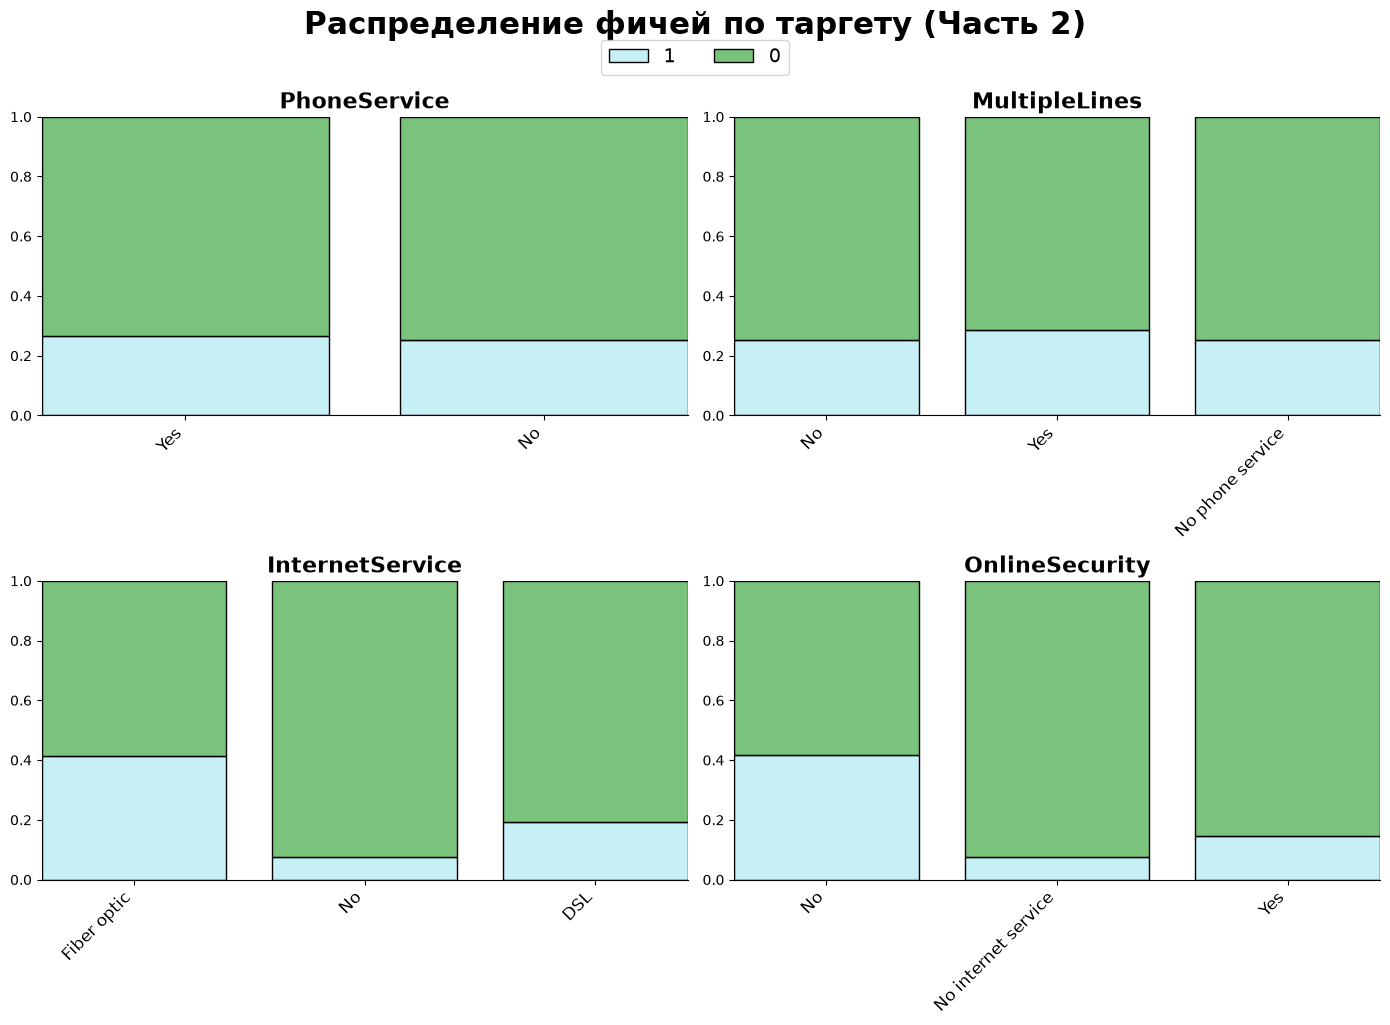

In [14]:
# Выводим ВТОРУЮ четверку (индексы 4, 5, 6, 7)
plot_feature_batch(categorical_cols[4:8], batch_num=2)

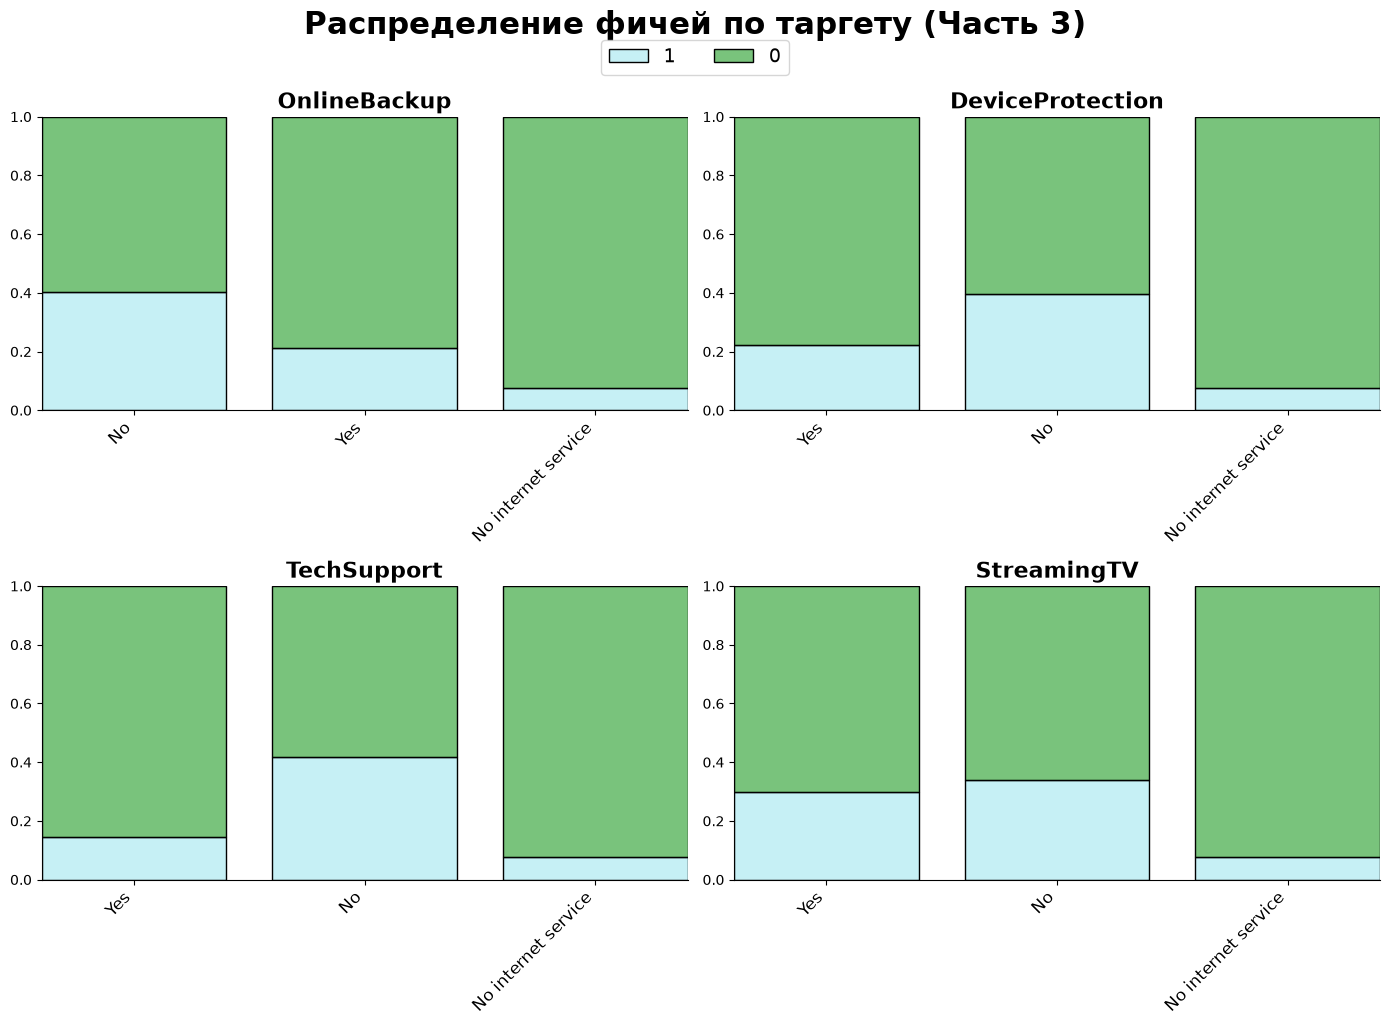

In [15]:
# Выводим ТРЕТЬЮ четверку (индексы 8, 9, 10, 11)
plot_feature_batch(categorical_cols[8:12], batch_num=3)

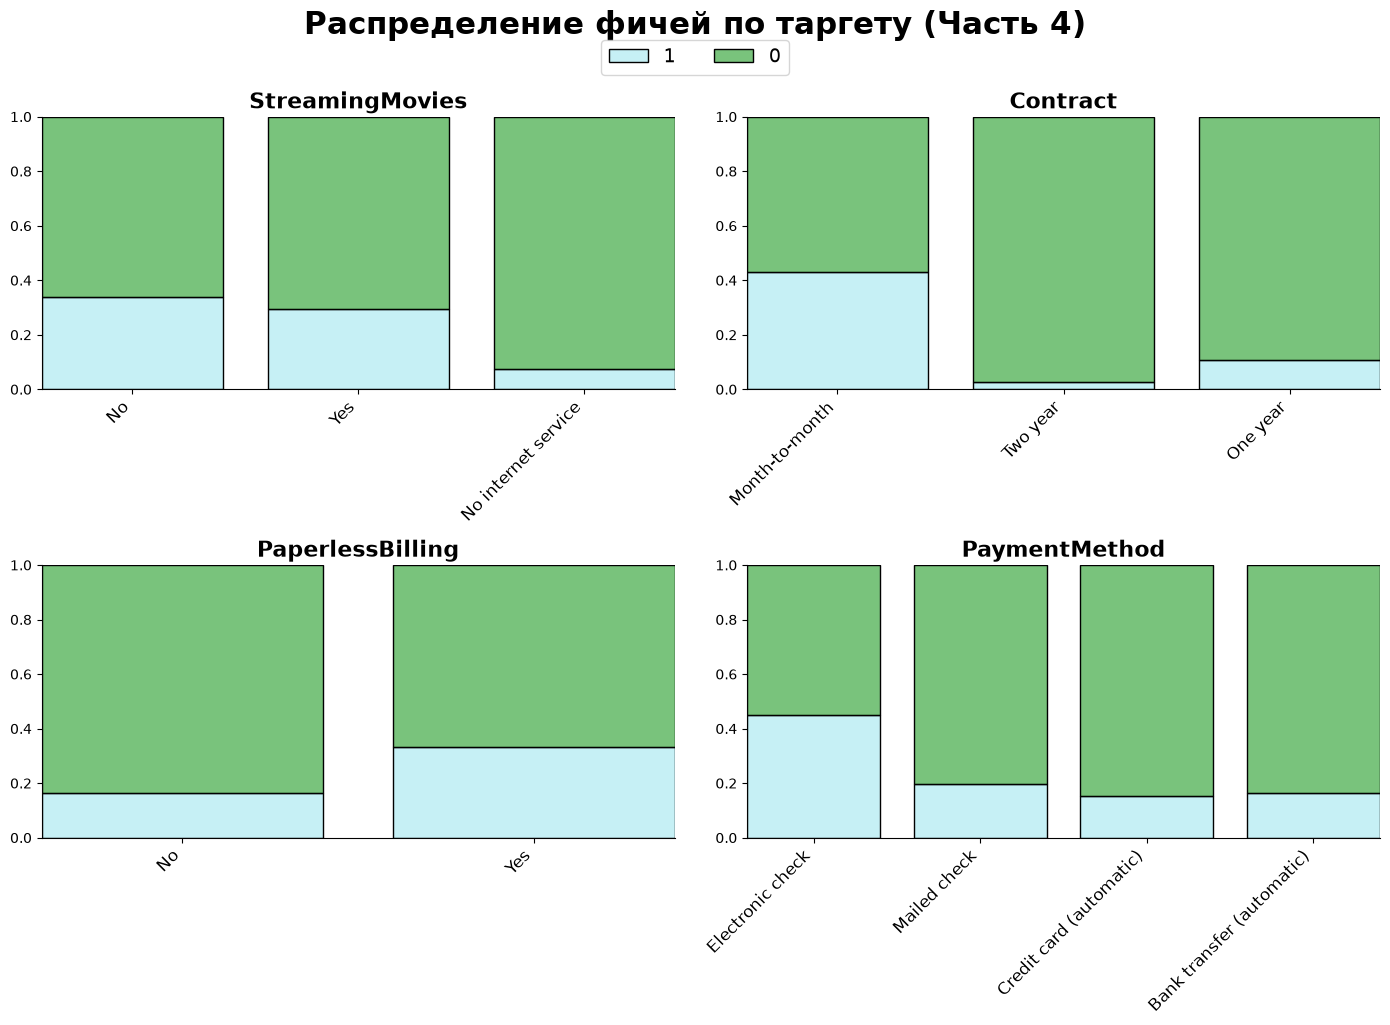

In [16]:
# Выводим ЧЕТВЕРТУЮ четверку (индексы 12, 13, 14, 15)
plot_feature_batch(categorical_cols[12:16], batch_num=4)

Отток не зависит от пола, наличия телефона или нескольких линий, 
кажется, больше всего вероятность оттока у тех, у кого оптоволоконное подключение, нет антивируса, тех поддержки, короткий контракт на месяц и оплата электронными чеками

посмотрим парные зависимости у числовых переменных

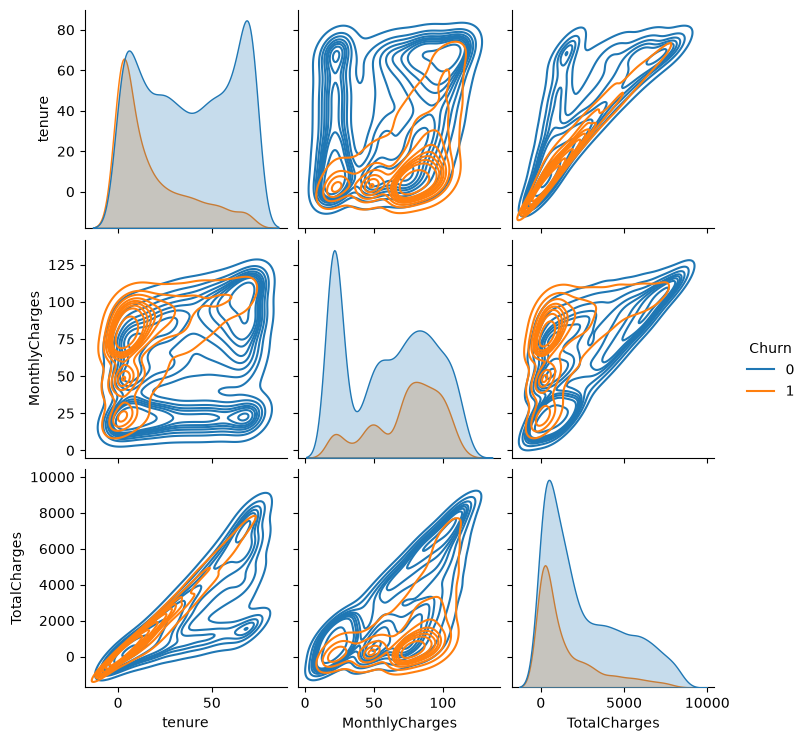

In [27]:
sns.pairplot(data_train, hue='Churn', kind='kde')

По нижнему ряду картинок (первые две) видно, что тотал это произведение продолжительности на ежемесячные траты, т е есть корреляция фичей.  Для линейных моделей одновременное использование всех трех фичей нежелательно, так как это может дестабилизировать веса.

Ежемесячные траты имеют несколько "горбов" как в оттоке, так и у оставшихся. Такое распределение данных сложно для линейных моделей, они отделяют данные плоскостью, а тут явно есть три тарифа эконом, стандарт и премиум. Линейная модель не сможет их разделить. 

Гораздо лучше обстоят дела с продолжительностью, там линейная модель должна увидеть один пик для оттока в самом начале - клиенты уходят практически сразу же после подключения, т е тут коэффициент будет отрицательным (чем дольше клиент, тем меньше вероятность уйти) и весомым. 

Нелинейные модели (деревья) умеют выделять локальные области, поэтому они лучше справятся с горбамии, смогут выделить в отдельную область низкую продолжительность и премиум тариф как зону высокого риска

посмотрим матрицу корреляций категориальных переменных

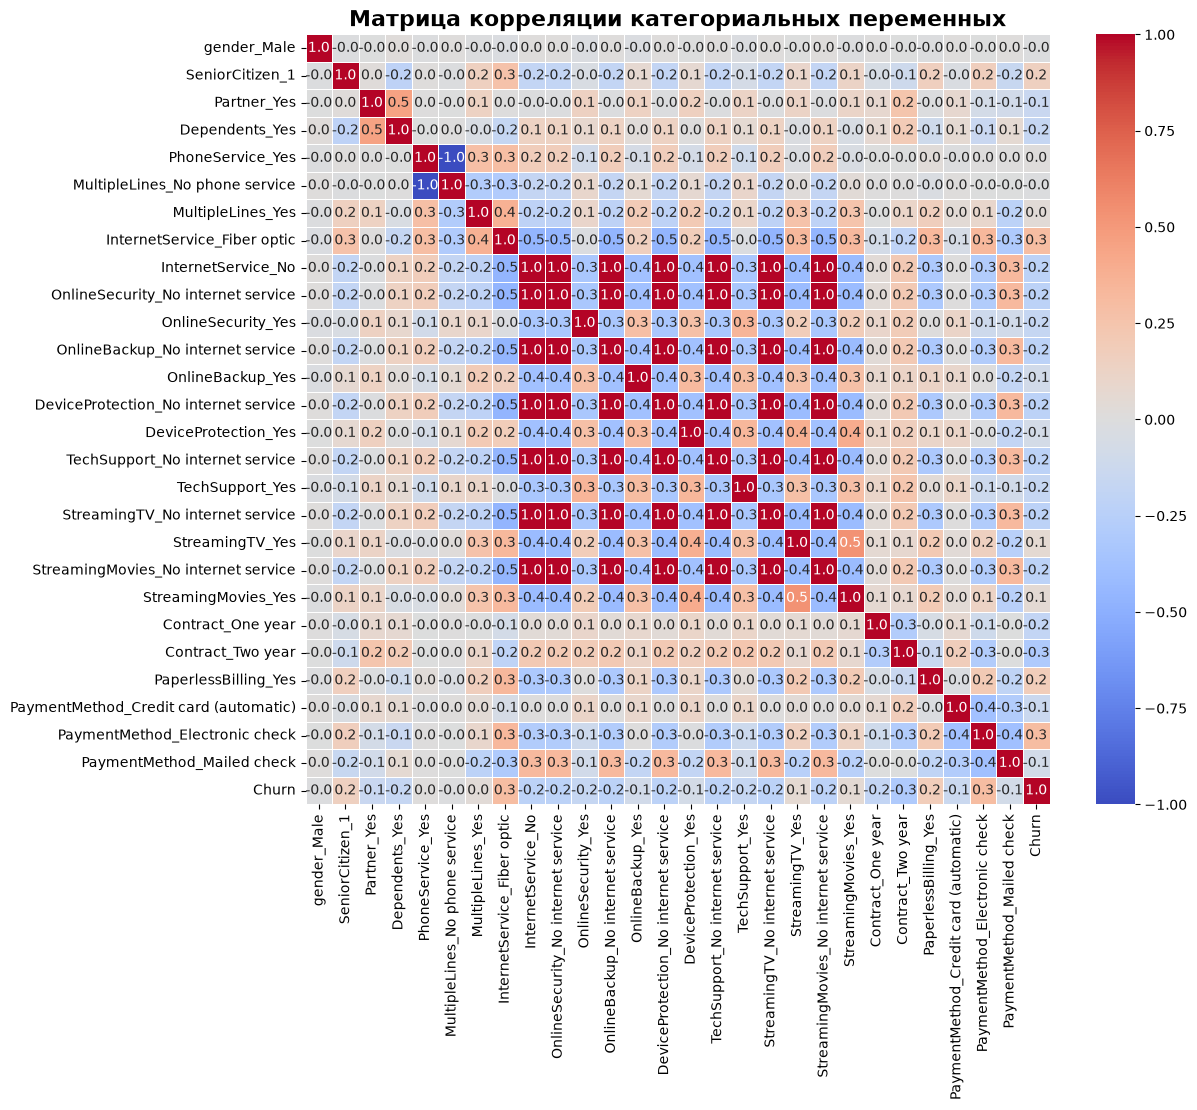

<Figure size 640x480 with 0 Axes>

In [28]:
df_encoded = pd.get_dummies(data_train, columns=categorical_cols, drop_first=True, dtype=int)

encoded_only_cols = [col for col in df_encoded.columns if any(col.startswith(orig) for orig in categorical_cols)]

# можем добавить еще и таргет Churn, чтобы посмотреть корреляцию с ним
encoded_only_cols.append('Churn')

# 3. Строим хитмап строго по отфильтрованным колонкам
plt.figure(figsize=(12, 10)) # Задаем адекватный размер полотна
sns.heatmap(
    df_encoded[encoded_only_cols].corr(), 
    cmap='coolwarm',                      
    annot=True,
    fmt=".1f",
    linewidths=0.5
)
plt.title('Матрица корреляции категориальных переменных', weight='bold', fontsize=16)
plt.show()
plt.tight_layout()



Из матрицы видно, что есть:

записимость между 'PhoneService' в ответе 'Yes' и 'MultipleLines' в ответе 'No phone service'

зависимости между 'InternetService' в ответе 'No' и следующими фичами с вариантом ответа 'No internet service': 

            'OnlineSecurity'
            
            'OnlineBackup'
            
            'DeviceProtection'
            
            'TechSupport'
            
            'StreamingTV'
            
            'StreamingMovies'

Бизнес-логика для 'PhoneService' в ответе 'Yes' и 'MultipleLines' в ответе 'No phone service': если человек ответил «Нет» на первый вопрос, оператор в системе автоматически проставляет «Нет телефонного сервиса» во втором вопросе. Клиент физически не может ответить «Да» или «Нет» про количество линий, если у него вообще нет кабеля. Одно подмножество данных полностью предопределяет другое.

Вторую зависимость также можно обьяснить кодировкой ответов. Если есть интернет, то обычно предлагают доп пакет из услуг, но если интернет не подключен, то и предлагать такие услуги нет смысла.
Если мы не глядя перекодируем 3 варианта ответов в числа в фичах  'OnlineSecurity', 'OnlineBackup' 'DeviceProtection' 'TechSupport' 'StreamingTV' 'StreamingMovies'(через One-Hot Encoding), у нас появится несколько колонок, которые будут абсолютно дублировать друг друга. 

Чтобы уйти от мультиколлинеарности в этих двух случаях мы можем:


Для блока про доп услуги для интеренета удалить колонки с ответами "No internet service".
Эти колонки состоят из тех же самых единиц и нулей, что и колонка InternetService_No. Оставляем только её, а остальные стираем:

 • OnlineSecurity_No internet service

 • OnlineBackup_No internet service

 • DeviceProtection_No internet service

 • TechSupport_No internet service

 • StreamingTV_No internet service

 • StreamingMovies_No internet service

Удаляем MultipleLines_No phone service - этот дубликат PhoneService_No

У нас остались MultipleLines_No и MultipleLines_Yes - оставим только MultipleLines_Yes

Удалим также InternetService_No (если DSL и Fiber равны 0, модель сама поймет, что интернета нет)

Для доп услуг интернета (после удаления категории No internet service на Шаге 1) у нас остались пары _No и _Yes. Удаляем все _No:


  • OnlineSecurity_No

  • OnlineBackup_No

  • DeviceProtection_No

  • TechSupport_No

  • StreamingTV_No
  
  • StreamingMovies_No

Также не забудем удалить total charges в численных фичах

Разведочный анализ данных (EDA) проведен, мы нашли зависимости как в категориальных, так и числовых переменных.

Также сформулировали гипотезы что:
С большей вероятностью уйдут - новые клиенты (маленький tenure), которые подключили дорогие тарифы или дополнительные услуги (высокий MonthlyCharges).

Отток не зависит от пола, наличия телефона или нескольких линий.
Ввероятность оттока выше у тех, у кого оптоволоконное подключение, нет антивируса, тех поддержки, короткий контракт на месяц и оплата электронными чеками.

Перейдем к следующим этапам, а именно подготовки датасета и линейным моделям 